# Thực nghiệm — Thử tham số cho 4 mô hình trên tập A+B
 Dữ liệu đầu vào chuyển sang tập A+B gồm 38 đặc trưng (36 đặc trưng gốc và 2 đặc trưng bổ sung từ học kỳ 1).
- Logistic Regression, Random Forest và SVM: so sánh cấu hình gốc với cấu hình thử như notebook tập A.
- XGBoost: so sánh learning_rate=0.1 với learning_rate=0.05 như notebook XGBoost tập A.
- Giữ nguyên các tham số còn lại, tiền xử lý, 5-fold Stratified CV, shuffle=True, random_state=42.
- Chỉ số chính: CV Macro-F1 trung bình.
Không sử dụng test.csv; mọi đánh giá thực hiện trên development.csv.

## 1. Cấu hình và tham số thử

| Mô hình | Tham số thay đổi | Cấu hình gốc | Cấu hình thử |
|---|---|---:|---:|
| Logistic Regression | `tol` | 0.0001 | 0.001 |
| Random Forest | `min_samples_split` | 2 | 5 |
| SVM | `shrinking` | True | False |
| XGBoost | `learning_rate` | 0.1 | 0.05 |

Các tham số khác được giữ nguyên theo đúng hai notebook thực nghiệm trên tập A.


In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.svm import SVC
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import make_scorer, recall_score
from xgboost import XGBClassifier

# Tìm thư mục gốc dự án.
cwd = Path.cwd().resolve()
candidates = (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
project_dir = next(
    (
        folder for folder in candidates
        if (folder / "feature_b" / "common.py").is_file()
        and (folder / "data" / "processed" / "development.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục ML01_Student_Dropout chứa "
        "feature_b/common.py và data/processed/development.csv. "
        "Hãy mở đúng repository trong VS Code."
    )

sys.path.insert(0, str(project_dir / "feature_b"))
from common import (
    evaluate, load_development,
    CATEGORICAL_COLUMNS, BINARY_COLUMNS, NUMERIC_COLUMNS
)

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-16_ThuThamSo_4MoHinh_TapAB_Khoi"

N_FOLDS = 5
SEED = 42

print("Project:", project_dir)
print("Dữ liệu:", data_path)
print("Thư mục lưu kết quả:", output_dir)
print("scikit-learn:", sklearn.__version__)
print("xgboost:", __import__("xgboost").__version__)


Project: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout
Dữ liệu: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\data\processed\development.csv
Thư mục lưu kết quả: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-16_ThuThamSo_4MoHinh_TapAB_Khoi
scikit-learn: 1.9.1
xgboost: 3.4.1


## 2. Khai báo cấu hình của bốn mô hình




In [2]:
# Ba mô hình trong notebook thu_tham_so_3_mo_hinh_A_Khoi.ipynb
configs = {
    "Logistic Regression": {
        "class": LogisticRegression,
        "scale_numeric": True,
        "baseline": {
            "C": 1.0, "tol": 0.0001, "class_weight": "balanced",
            "solver": "lbfgs", "max_iter": 3000,
        },
        "trial": {
            "C": 1.0, "tol": 0.001, "class_weight": "balanced",
            "solver": "lbfgs", "max_iter": 3000,
        },
        "changed_parameter": "tol: 0.0001 -> 0.001",
    },
    "Random Forest": {
        "class": RandomForestClassifier,
        "scale_numeric": False,
        "baseline": {
            "n_estimators": 300, "max_depth": None,
            "min_samples_split": 2, "min_samples_leaf": 1,
            "class_weight": "balanced", "random_state": SEED, "n_jobs": 1,
        },
        "trial": {
            "n_estimators": 300, "max_depth": None,
            "min_samples_split": 5, "min_samples_leaf": 1,
            "class_weight": "balanced", "random_state": SEED, "n_jobs": 1,
        },
        "changed_parameter": "min_samples_split: 2 -> 5",
    },
    "SVM": {
        "class": SVC,
        "scale_numeric": True,
        "baseline": {
            "kernel": "rbf", "C": 10, "gamma": 0.01,
            "shrinking": True, "class_weight": "balanced",
        },
        "trial": {
            "kernel": "rbf", "C": 10, "gamma": 0.01,
            "shrinking": False, "class_weight": "balanced",
        },
        "changed_parameter": "shrinking: True -> False",
    },
}

# XGBoost theo notebook thu_tham_so_XGB_A.ipynb của Khởi.
xgb_configs = {
    "XGBoost": {
        "baseline": {
            "n_estimators": 150, "max_depth": 3, "learning_rate": 0.1,
        },
        "trial": {
            "n_estimators": 150, "max_depth": 3, "learning_rate": 0.05,
        },
        "changed_parameter": "learning_rate: 0.1 -> 0.05",
    }
}

config_rows = []
for model_name, item in configs.items():
    for version in ("baseline", "trial"):
        config_rows.append({
            "Mô hình": model_name,
            "Cấu hình": "Gốc" if version == "baseline" else "Thử",
            "Tham số thay đổi": item["changed_parameter"],
            "Tham số thiết lập": ", ".join(
                f"{key}={value!r}" for key, value in item[version].items()
            ),
            "Chuẩn hóa cột số": "Có" if item["scale_numeric"] else "Không",
        })

for model_name, item in xgb_configs.items():
    for version in ("baseline", "trial"):
        config_rows.append({
            "Mô hình": model_name,
            "Cấu hình": "Gốc" if version == "baseline" else "Thử",
            "Tham số thay đổi": item["changed_parameter"],
            "Tham số thiết lập": ", ".join(
                f"{key}={value!r}" for key, value in item[version].items()
            ),
            "Chuẩn hóa cột số": "Không",
        })

config_table = pd.DataFrame(config_rows)
display(config_table)


,Mô hình,Cấu hình,Tham số thay đổi,Tham số thiết lập,Chuẩn hóa cột số
0,Logistic Regression,Gốc,tol: 0.0001 -> 0.001,"C=1.0, tol=0.0001, class_weight='balanced', so...",Có
1,Logistic Regression,Thử,tol: 0.0001 -> 0.001,"C=1.0, tol=0.001, class_weight='balanced', sol...",Có
2,Random Forest,Gốc,min_samples_split: 2 -> 5,"n_estimators=300, max_depth=None, min_samples_...",Không
3,Random Forest,Thử,min_samples_split: 2 -> 5,"n_estimators=300, max_depth=None, min_samples_...",Không
4,SVM,Gốc,shrinking: True -> False,"kernel='rbf', C=10, gamma=0.01, shrinking=True...",Có
5,SVM,Thử,shrinking: True -> False,"kernel='rbf', C=10, gamma=0.01, shrinking=Fals...",Có
6,XGBoost,Gốc,learning_rate: 0.1 -> 0.05,"n_estimators=150, max_depth=3, learning_rate=0.1",Không
7,XGBoost,Thử,learning_rate: 0.1 -> 0.05,"n_estimators=150, max_depth=3, learning_rate=0.05",Không


## 3. Huấn luyện và đánh giá trên tập A+B

Dùng chung một cách chia `StratifiedKFold` cho cả tám lần đánh giá (4 mô hình × 2 cấu hình). Hai đặc trưng B được đưa vào pipeline đúng nhóm: `hk1_pass_rate` thuộc nhóm số và `hk1_zero_enrolled` thuộc nhóm nhị phân.


In [3]:
X_a, X_ab, y = load_development(data_path)

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []

# Đánh giá Logistic Regression, Random Forest và SVM.
for model_name, item in configs.items():
    for version in ("baseline", "trial"):
        display_name = f"{model_name} - {'Gốc' if version == 'baseline' else 'Thử'}"
        print(f"Đang đánh giá trên A+B: {display_name}")

        model = item["class"](**item[version])
        summary, fold_scores = evaluate(
            display_name, model, item["scale_numeric"], "A+B", X_ab, y, folds
        )
        summary["model"] = model_name
        summary["configuration"] = "Gốc" if version == "baseline" else "Thử"
        summary["changed_parameter"] = item["changed_parameter"]
        summary_rows.append(summary)

        fold_scores["configuration"] = (
            "Gốc" if version == "baseline" else "Thử"
        )
        fold_tables.append(fold_scores)

# Pipeline XGBoost: giữ cách tiền xử lý trong notebook XGBoost tập A,
# đồng thời bổ sung hai cột B vào đúng nhóm đặc trưng.
numeric_ab = NUMERIC_COLUMNS + ["hk1_pass_rate"]
binary_ab = BINARY_COLUMNS + ["hk1_zero_enrolled"]

def build_xgb_pipeline(params):
    preprocessing = ColumnTransformer([
        ("category", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLUMNS),
        ("numeric", "passthrough", numeric_ab),
        ("binary", "passthrough", binary_ab),
    ])
    model = XGBClassifier(
        **params,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=SEED,
        n_jobs=1,
    )
    return Pipeline([("preprocessing", preprocessing), ("model", model)])

xgb_scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted",
    "recall_dropout": make_scorer(
        recall_score, labels=[0], average="macro", zero_division=0
    ),
}

for version in ("baseline", "trial"):
    params = xgb_configs["XGBoost"][version]
    display_name = f"XGBoost - {'Gốc' if version == 'baseline' else 'Thử'}"
    print(f"Đang đánh giá trên A+B: {display_name}")
    started = time.perf_counter()
    scores = cross_validate(
        build_xgb_pipeline(params), X_ab, y,
        cv=folds, scoring=xgb_scoring,
        return_train_score=True, n_jobs=1, error_score="raise",
    )
    elapsed = time.perf_counter() - started

    fold_scores = pd.DataFrame({
        "model": "XGBoost",
        "data": "A+B",
        "fold": range(1, N_FOLDS + 1),
        "macro_f1": scores["test_macro_f1"],
        "train_macro_f1": scores["train_macro_f1"],
        "test_accuracy": scores["test_accuracy"],
        "test_weighted_f1": scores["test_weighted_f1"],
        "test_recall_dropout": scores["test_recall_dropout"],
        "fit_time": scores["fit_time"],
        "score_time": scores["score_time"],
        "configuration": "Gốc" if version == "baseline" else "Thử",
    })
    fold_tables.append(fold_scores)

    summary_rows.append({
        "model": "XGBoost",
        "data": "A+B",
        "features": X_ab.shape[1],
        "cv_macro_f1": scores["test_macro_f1"].mean(),
        "cv_macro_f1_std": scores["test_macro_f1"].std(ddof=1),
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_weighted_f1": scores["test_weighted_f1"].mean(),
        "cv_recall_dropout": scores["test_recall_dropout"].mean(),
        "train_macro_f1": scores["train_macro_f1"].mean(),
        "mean_fit_seconds": scores["fit_time"].mean(),
        "total_seconds": elapsed,
        "configuration": "Gốc" if version == "baseline" else "Thử",
        "changed_parameter": xgb_configs["XGBoost"]["changed_parameter"],
    })

results = pd.DataFrame(summary_rows)
fold_results = pd.concat(fold_tables, ignore_index=True, sort=False)

comparison = results.pivot(
    index="model", columns="configuration", values="cv_macro_f1"
).reset_index()
comparison["Chênh lệch (Thử - Gốc)"] = comparison["Thử"] - comparison["Gốc"]
comparison = comparison.sort_values(
    "Chênh lệch (Thử - Gốc)", ascending=False
).reset_index(drop=True)

print("\nKết quả từng cấu hình trên A+B:")
display(results.round(6))

print("\nSo sánh cấu hình gốc và cấu hình thử trên A+B:")
display(comparison.round(6))


3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang đánh giá trên A+B: Logistic Regression - Gốc
Đang đánh giá trên A+B: Logistic Regression - Thử
Đang đánh giá trên A+B: Random Forest - Gốc
Đang đánh giá trên A+B: Random Forest - Thử
Đang đánh giá trên A+B: SVM - Gốc
Đang đánh giá trên A+B: SVM - Thử
Đang đánh giá trên A+B: XGBoost - Gốc
Đang đánh giá trên A+B: XGBoost - Thử

Kết quả từng cấu hình trên A+B:


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate,configuration,changed_parameter,cv_macro_f1_std,cv_accuracy,cv_weighted_f1,cv_recall_dropout,train_macro_f1,mean_fit_seconds,total_seconds
0,Logistic Regression,A+B,38,0.712076,0.737027,0.606299,0.816072,Gốc,tol: 0.0001 -> 0.001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Logistic Regression,A+B,38,0.712236,0.740545,0.603150,0.816072,Thử,tol: 0.0001 -> 0.001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Random Forest,A+B,38,0.722734,0.754617,0.519685,0.879457,Gốc,min_samples_split: 2 -> 5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Random Forest,A+B,38,0.722283,0.743184,0.549606,0.868704,Thử,min_samples_split: 2 -> 5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,SVM,A+B,38,0.717298,0.738786,0.595276,0.835314,Gốc,shrinking: True -> False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,SVM,A+B,38,0.717298,0.738786,0.595276,0.835314,Thử,shrinking: True -> False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,XGBoost,A+B,38,0.714158,NaN,NaN,NaN,Gốc,learning_rate: 0.1 -> 0.05,0.009665,0.784117,0.773589,0.774789,0.809940,0.460802,2.676035
7,XGBoost,A+B,38,0.701923,NaN,NaN,NaN,Thử,learning_rate: 0.1 -> 0.05,0.014660,0.777334,0.765125,0.767760,0.762234,0.474532,2.752238



So sánh cấu hình gốc và cấu hình thử trên A+B:


configuration,model,Gốc,Thử,Chênh lệch (Thử - Gốc)
0,Logistic Regression,0.712076,0.712236,0.000160
1,SVM,0.717298,0.717298,0.000000
2,Random Forest,0.722734,0.722283,-0.000451
3,XGBoost,0.714158,0.701923,-0.012235


## 4. Xuất kết quả và biểu đồ

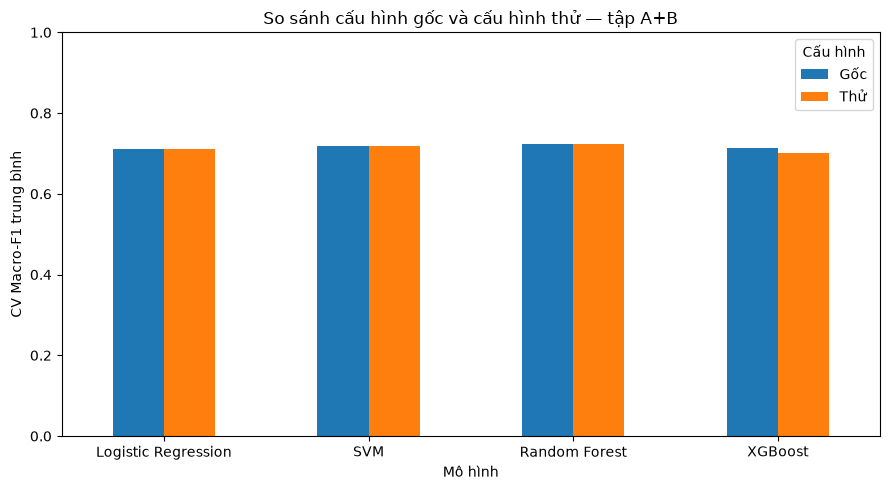


Đã lưu kết quả vào:
C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-16_ThuThamSo_4MoHinh_TapAB_Khoi
 - ket_qua.xlsx
 - ket_qua_tong_hop.csv
 - diem_tung_fold.csv
 - so_sanh_goc_va_thu.csv
 - so_sanh_macro_f1.png


In [4]:
output_dir.mkdir(parents=True, exist_ok=True)

excel_path = output_dir / "ket_qua.xlsx"
summary_csv = output_dir / "ket_qua_tong_hop.csv"
fold_csv = output_dir / "diem_tung_fold.csv"
comparison_csv = output_dir / "so_sanh_goc_va_thu.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người thực hiện": "Nguyễn Hoàng Khởi",
    "Ngày thực nghiệm": "16/11/2026",
    "Tập đặc trưng": "A+B",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y),
    "Số đặc trưng": X_ab.shape[1],
    "Kiểm định chéo": "StratifiedKFold",
    "Số fold": N_FOLDS,
    "Shuffle": True,
    "Random state": SEED,
    "Chỉ số chính": "CV Macro-F1 trung bình",
    "Thay đổi": (
        "LR: tol 0.0001 -> 0.001; "
        "RF: min_samples_split 2 -> 5; "
        "SVM: shrinking True -> False; "
        "XGBoost: learning_rate 0.1 -> 0.05"
    ),
    "scikit-learn": sklearn.__version__,
    "Số đặc trưng A+B": X_ab.shape[1],
}])

results.to_csv(summary_csv, index=False, encoding="utf-8-sig")
fold_results.to_csv(fold_csv, index=False, encoding="utf-8-sig")
comparison.to_csv(comparison_csv, index=False, encoding="utf-8-sig")

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    comparison.to_excel(writer, sheet_name="So sanh goc va thu", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    run_info.to_excel(writer, sheet_name="Thong tin thuc nghiem", index=False)

plot_data = comparison.set_index("model")[["Gốc", "Thử"]]
ax = plot_data.plot(kind="bar", figsize=(9, 5))
ax.set_ylim(0, 1)
ax.set_ylabel("CV Macro-F1 trung bình")
ax.set_xlabel("Mô hình")
ax.set_title("So sánh cấu hình gốc và cấu hình thử — tập A+B")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Cấu hình")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(image_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nĐã lưu kết quả vào:")
print(output_dir.resolve())
for path in (excel_path, summary_csv, fold_csv, comparison_csv, image_path):
    print(" -", path.name)


## 5. Nhận xét

Sau khi chạy xong, dựa vào bảng **So sánh cấu hình gốc và cấu hình thử trên A+B**:

- Chênh lệch dương: cấu hình thử có CV Macro-F1 cao hơn cấu hình gốc trên A+B.
- Chênh lệch âm: cấu hình gốc có CV Macro-F1 cao hơn cấu hình thử trên A+B.
- Chênh lệch gần 0: hai cấu hình cho kết quả tương đương trong lần đánh giá này.

Đối chiếu bảng này với kết quả tập A để nhận xét việc thay đổi tham số trên tập A+B. Không kết luận trước mô hình nào tốt hơn khi chưa chạy thực nghiệm.
